# 2. Exploratory data analysis

**DATA3800, autumn 2026. Group 8.**

Before any model, we look at the data: the shape of the target, how it moves over time, and how it relates to the features. The plotting functions are in `src/eda.py`. Each figure is saved to `figures/` so the report uses exactly the same images.

In [1]:
# Setup: find the repo, make src/ importable, and print the environment.
import platform, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib, numpy as np, pandas as pd, seaborn, sklearn
from IPython.display import Image, display

print("Python      ", platform.python_version())
for lib in (pd, np, sklearn, matplotlib, seaborn):
    print(f"{lib.__name__:<12}", lib.__version__)

pd.set_option("display.width", 160)

def show(name, width=820):
    """Display a figure that a pipeline step saved in figures/."""
    display(Image(filename=str(ROOT / "figures" / f"{name}.png"), width=width))

Python       3.14.2
pandas       3.0.6
numpy        2.5.4
sklearn      1.9.1
matplotlib   3.11.2
seaborn      0.13.2


In [2]:
import eda

df = eda.load_dataset()      # index converted to Oslo time
print(f"{len(df):,} hourly rows, {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
df[["load_mw", "temp_c", "load_lag_48h", "load_lag_168h"]].describe().round(1)

32,687 hourly rows, 2023-01-08 to 2026-09-30


,load_mw,temp_c,load_lag_48h,load_lag_168h
count,32687.0,32687.0,32687.0,32687.0
mean,3924.6,8.0,3927.9,3937.6
std,1313.2,8.6,1314.5,1318.6
min,1759.5,-22.5,1759.5,1759.5
25%,2860.0,1.6,2861.3,2863.5
50%,3604.0,8.4,3608.9,3623.0
75%,4903.9,14.8,4909.1,4928.5
max,8166.0,32.4,8166.0,8166.0


## 2.1 One variable at a time

### The shape of the target

Saved figures/eda_load_distribution.png


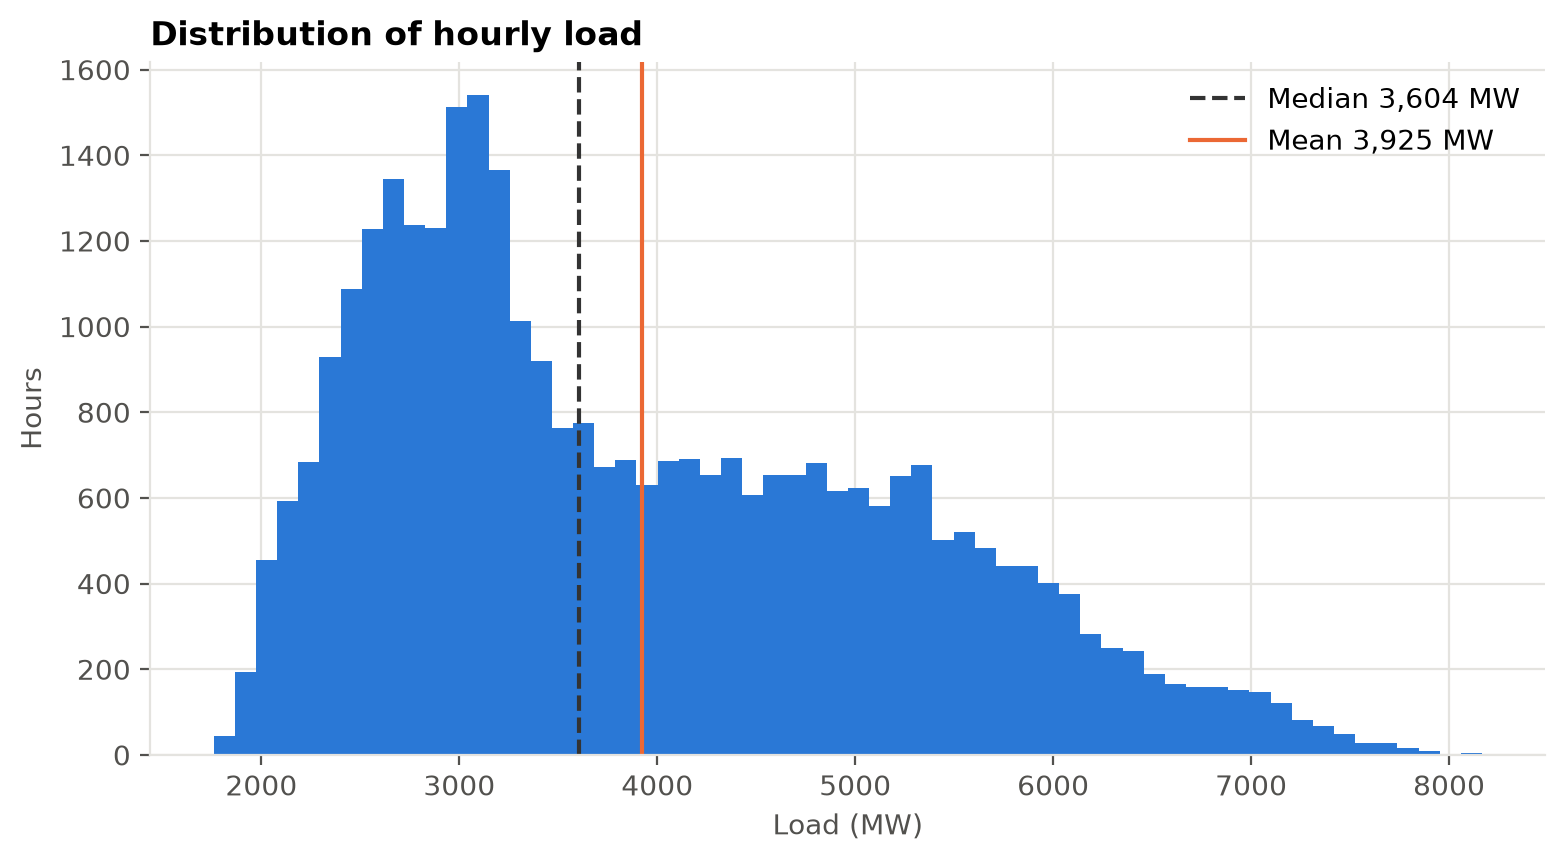

In [3]:
eda.plot_distribution(df)
show("eda_load_distribution")

The distribution is not symmetric. Most hours sit between 2,500 and 3,500 MW, with a long tail up to about 8,000 MW from cold winter hours. That tail pulls the mean (3,925 MW) about 320 MW above the median (3,604 MW). The rare high-load hours are also the ones that matter most for the grid, which is why we look at them separately in notebook 3.

### Load over time

Saved figures/eda_load_over_time.png


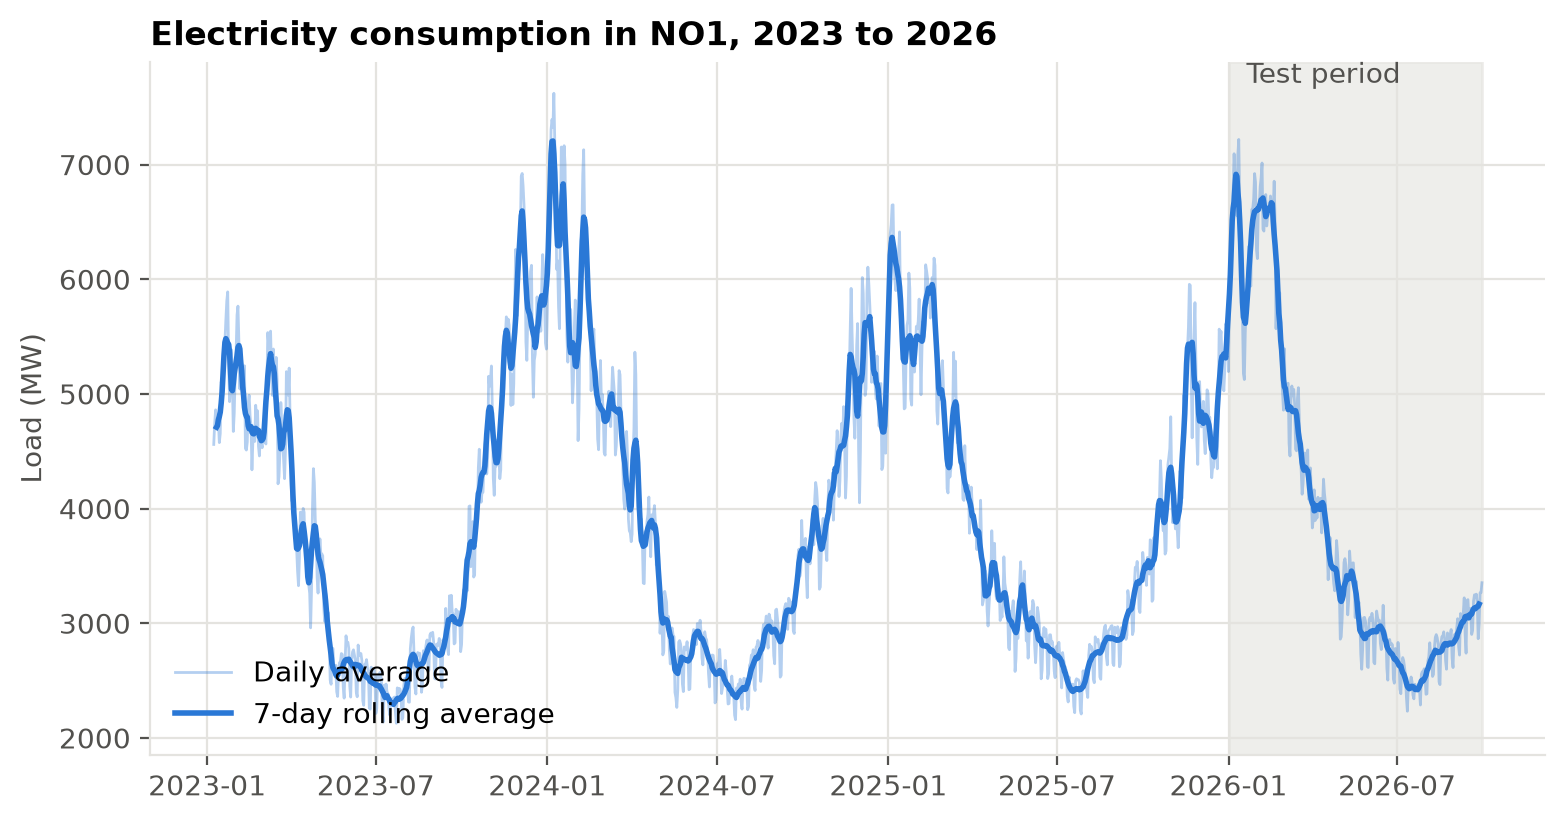

In [4]:
eda.plot_over_time(df)
show("eda_load_over_time")

A strong yearly cycle, with winter peaks more than twice the summer level. The shaded test period (2026) starts with a cold January and February, so the test set contains the hardest part of the year as well as an easy summer.

### Hour of day

Saved figures/eda_load_by_hour.png


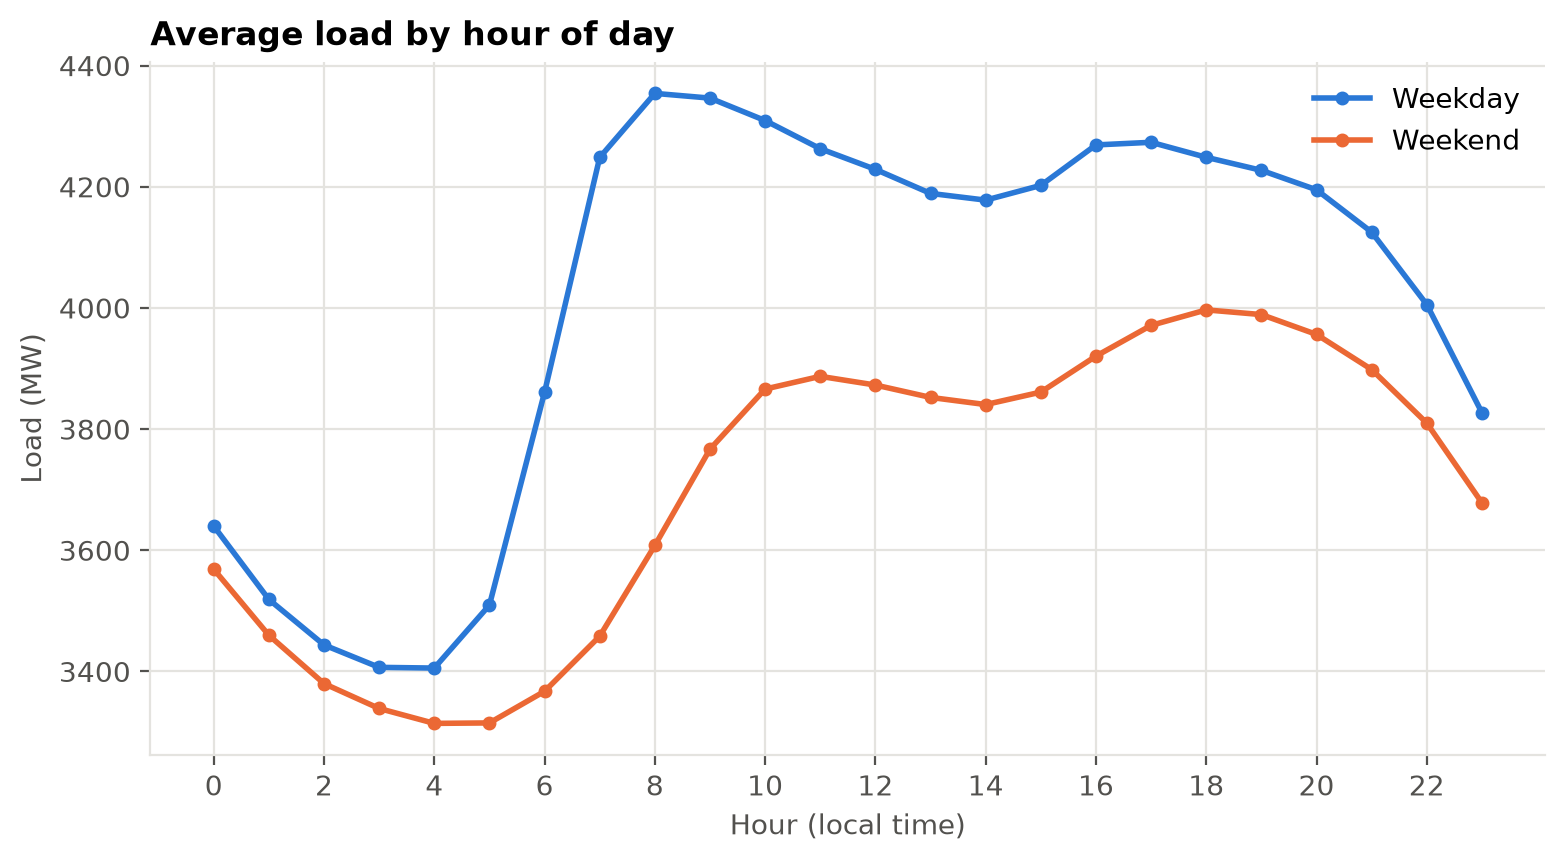

In [5]:
eda.plot_by_hour(df)
show("eda_load_by_hour")

Saved figures/eda_load_box_by_hour.png


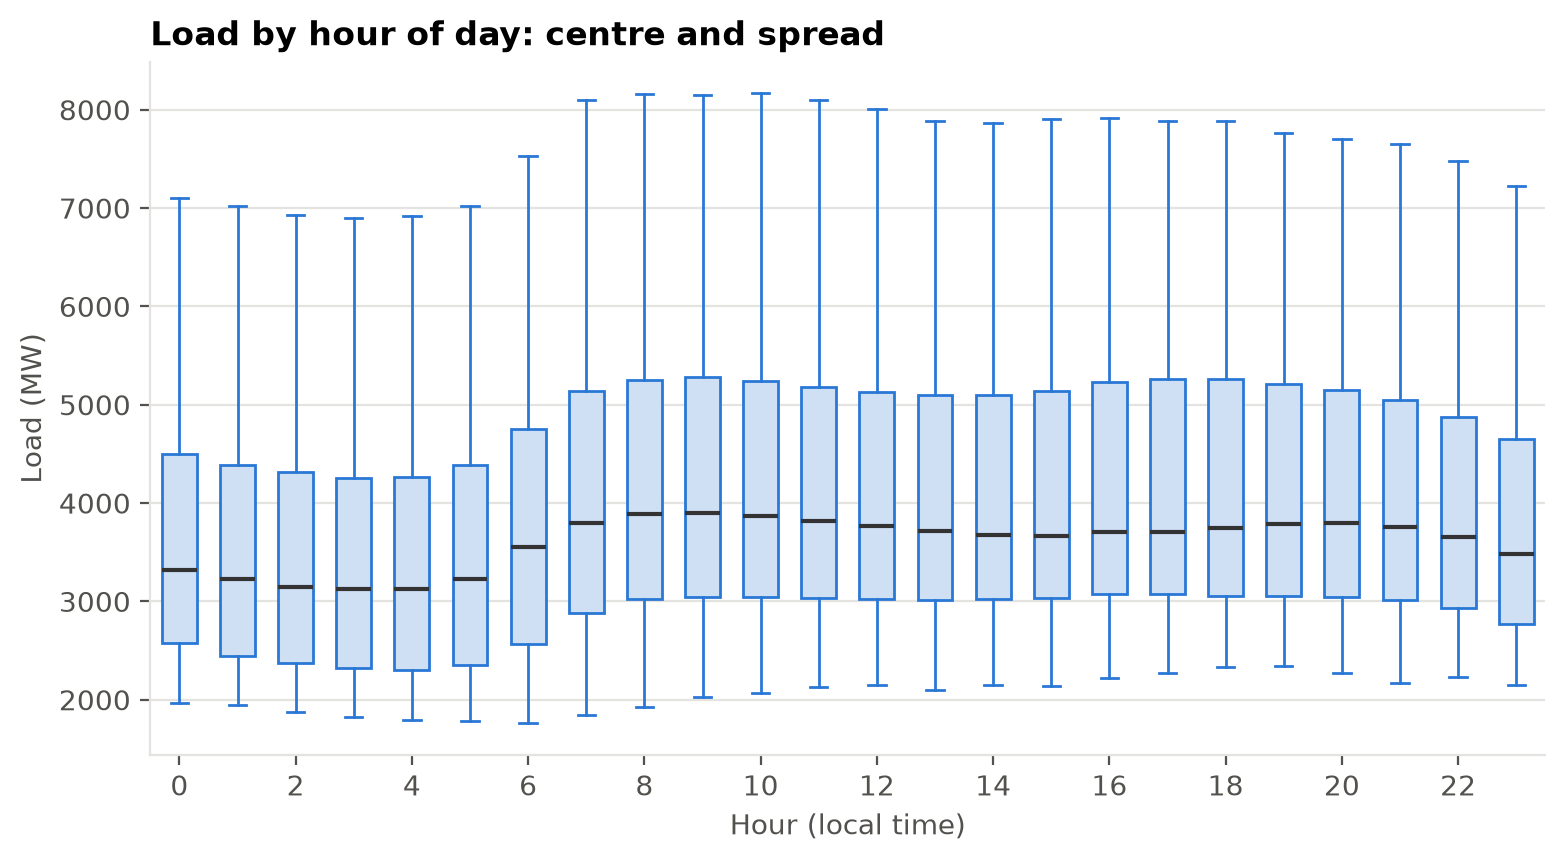

In [6]:
eda.plot_box_by_hour(df)
show("eda_load_box_by_hour")

Weekdays have a morning peak at 08:00 (about 4,350 MW on average) and a second, flatter peak in the late afternoon. Weekends start later and peak at 18:00. The box plot shows something the averages hide: the spread within one hour (about 1,900 to 2,250 MW between the quartiles) is far larger than the difference between hours. The season decides the level, the hour only shapes the day.

### Day of week and month

Saved figures/eda_load_by_weekday.png


Saved figures/eda_load_by_month.png


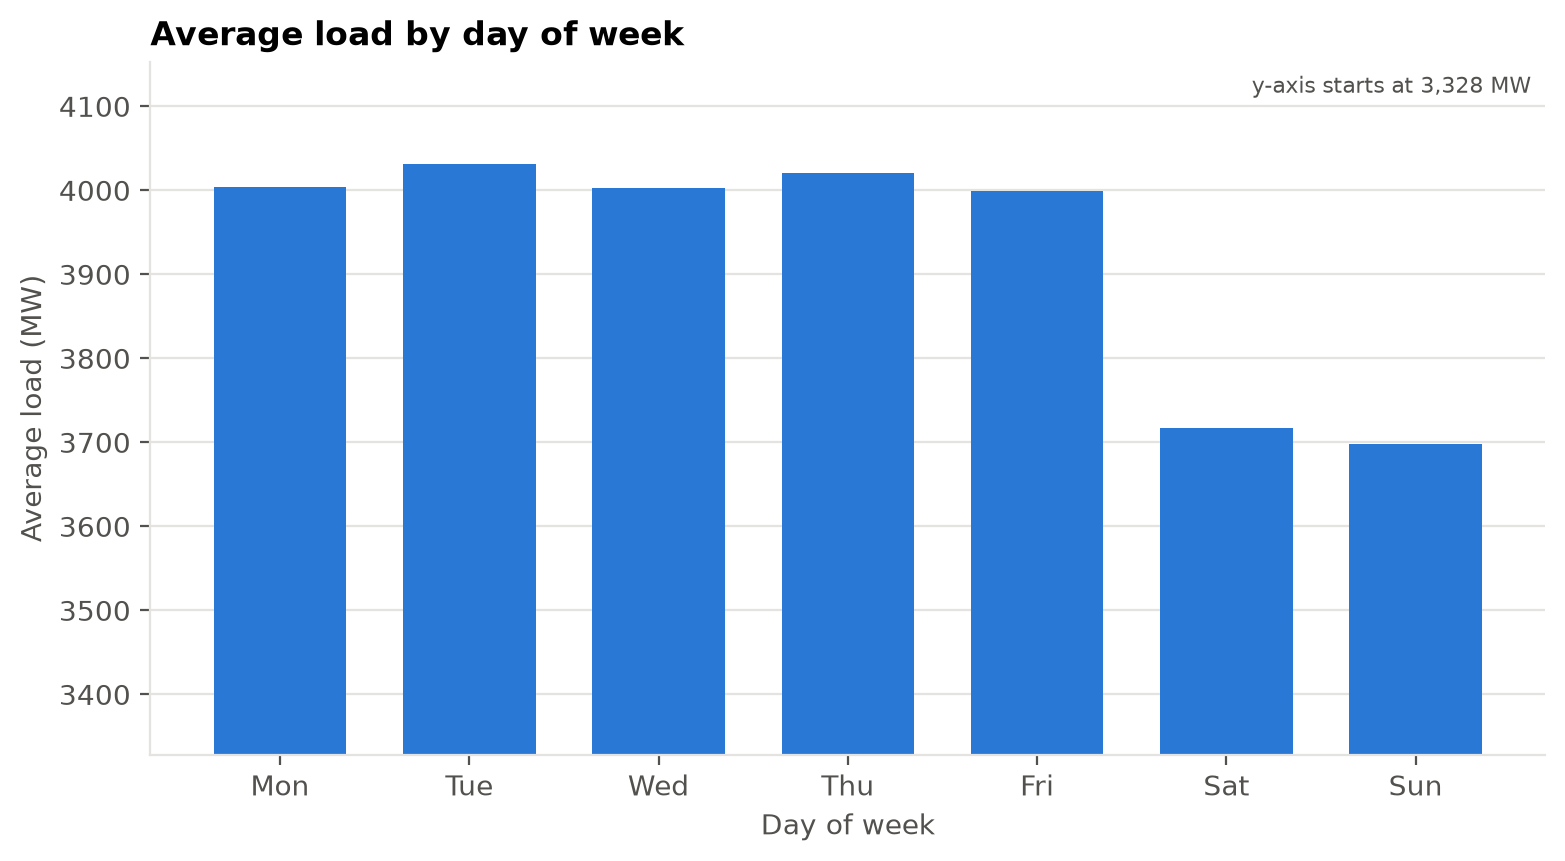

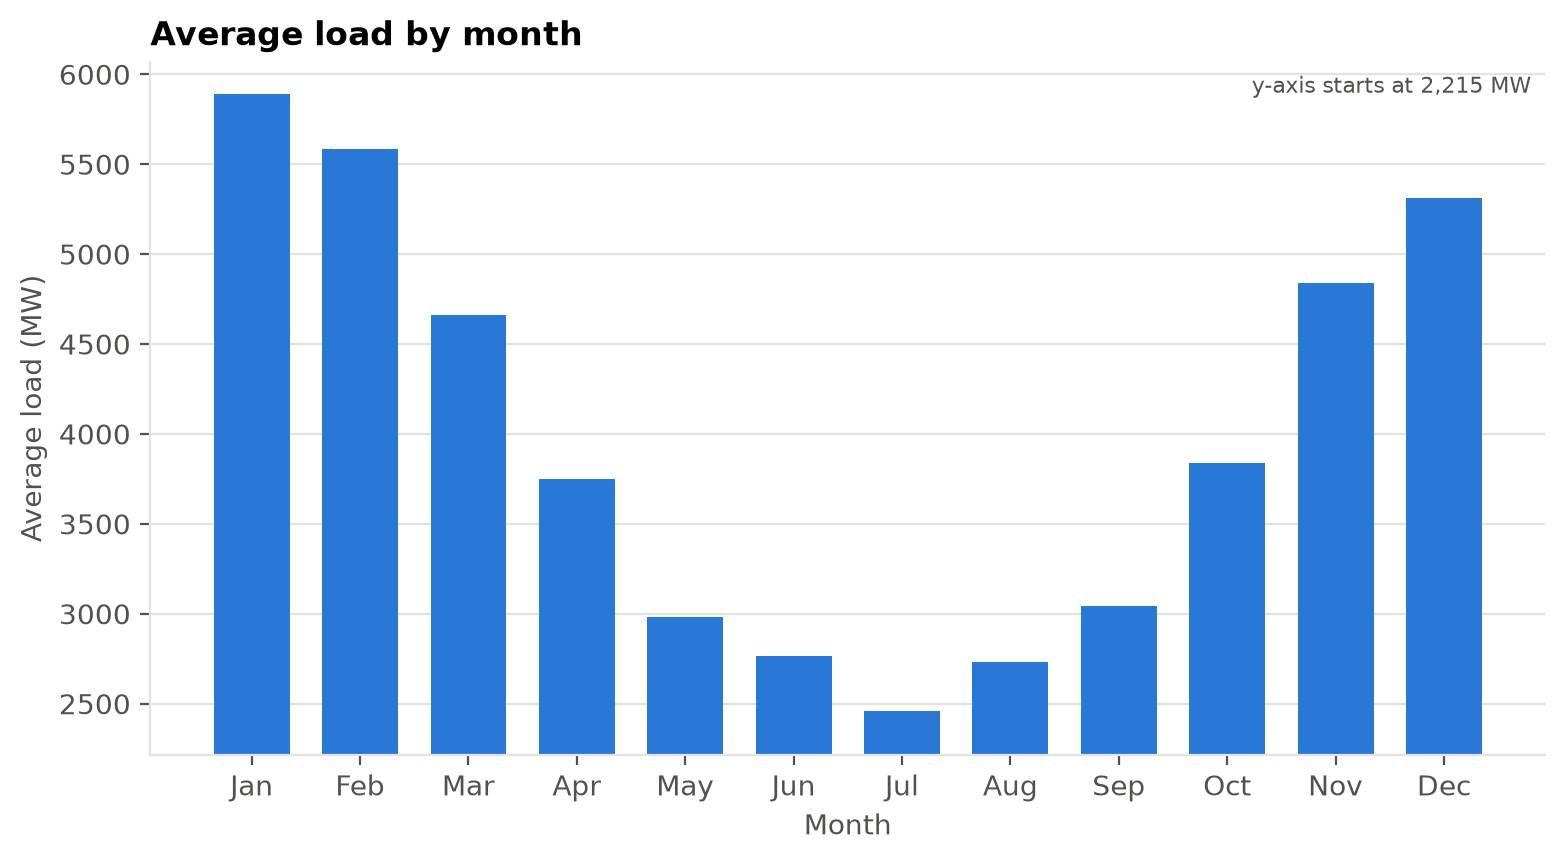

Weekdays are 8.2 % above weekends.
The highest month is 2.39 times the lowest.


In [7]:
by_weekday = df.groupby("weekday")["load_mw"].mean()
eda.plot_bars(by_weekday, eda.WEEKDAYS, "Average load by day of week", "Day of week", "eda_load_by_weekday")
by_month = df.groupby("month")["load_mw"].mean()
eda.plot_bars(by_month, [eda.MONTHS[m - 1] for m in by_month.index], "Average load by month", "Month", "eda_load_by_month")
show("eda_load_by_weekday", 640)
show("eda_load_by_month", 640)
print(f"Weekdays are {(df.loc[df.is_weekend == 0, 'load_mw'].mean() / df.loc[df.is_weekend == 1, 'load_mw'].mean() - 1) * 100:.1f} % above weekends.")
print(f"The highest month is {by_month.max() / by_month.min():.2f} times the lowest.")

Weekdays are about 8 % above weekends. January (about 5,900 MW) is 2.4 times July (about 2,500 MW). Both effects are regular, so calendar features should help a model.

## 2.2 Two variables at once

### Hour and day in one chart

Saved figures/eda_load_hour_weekday.png


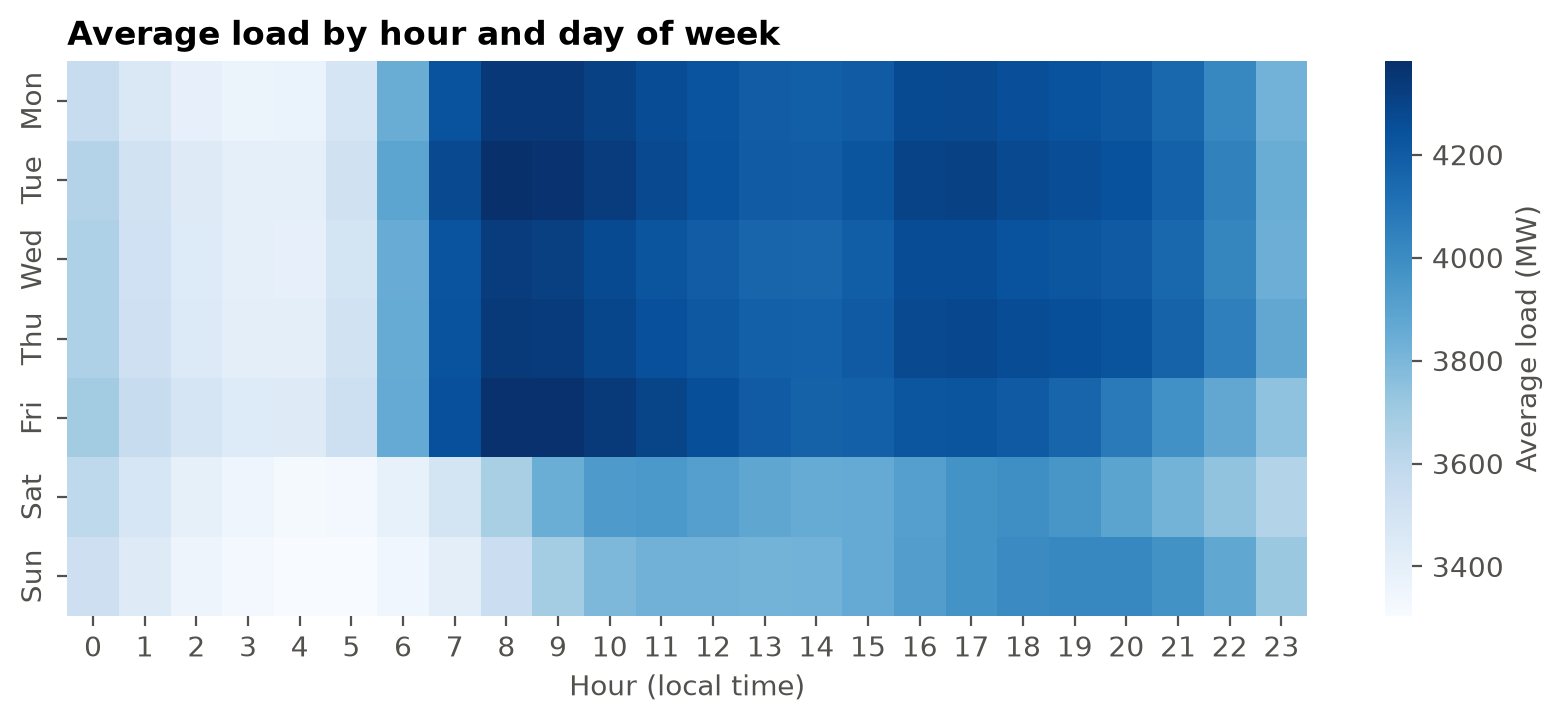

In [8]:
eda.plot_hour_weekday_heatmap(df)
show("eda_load_hour_weekday")

The working-day pattern runs Monday to Friday and stops at the weekend. Friday evening already looks a little like a weekend. This is the same information as a pivot table, readable in a second.

### Load against temperature

Saved figures/eda_load_vs_temperature.png
Saved figures/eda_load_vs_temperature_hourly.png


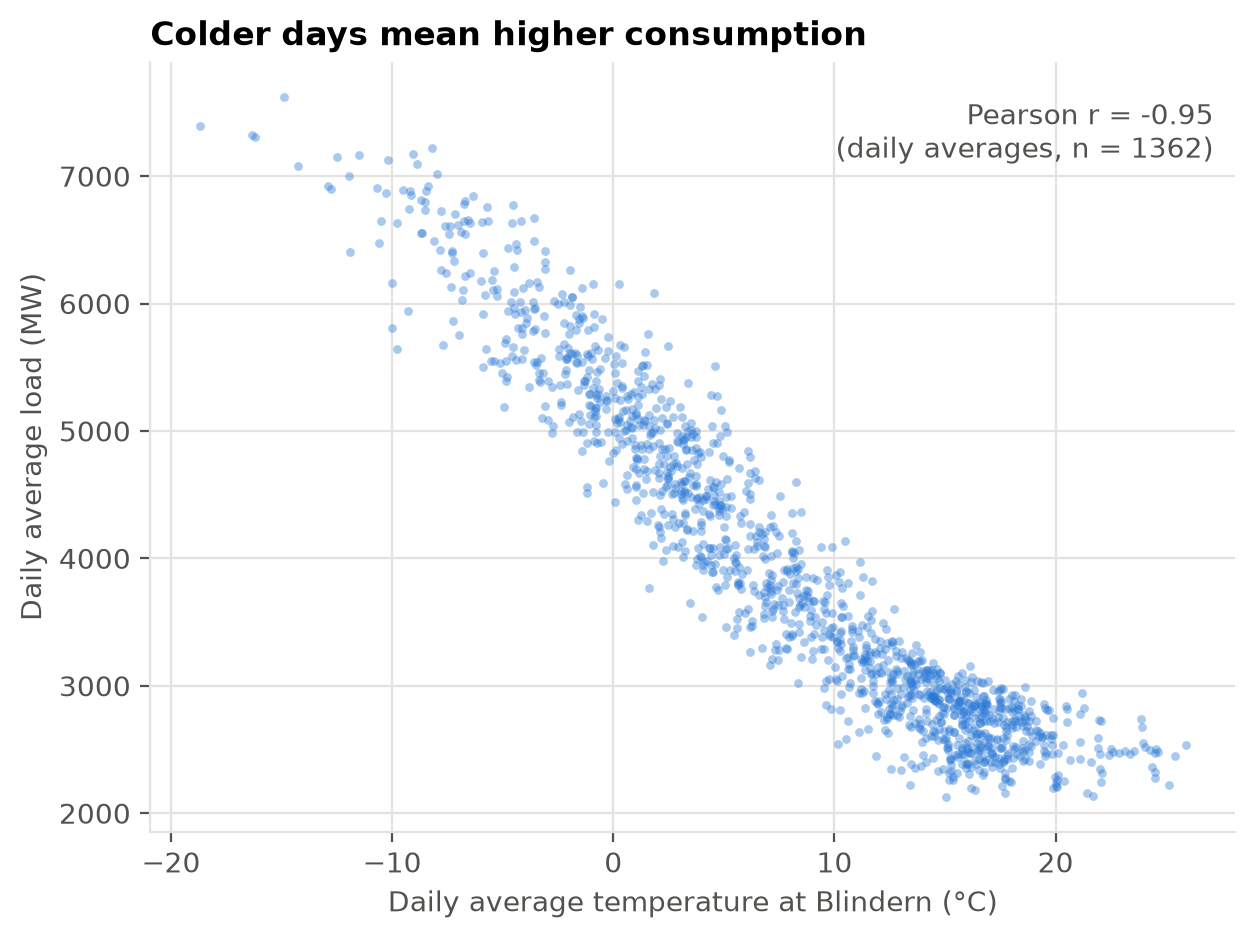

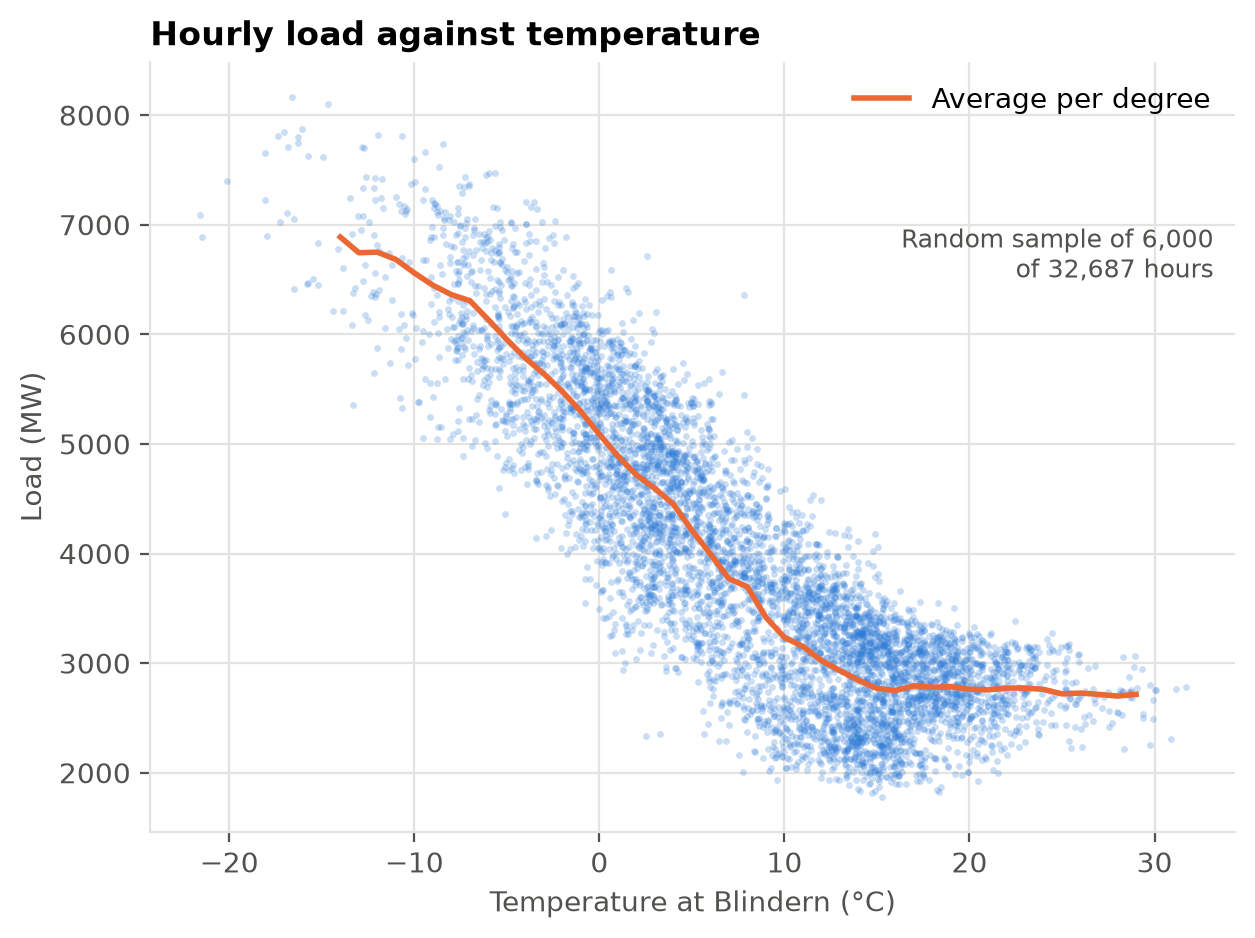

In [9]:
corr_daily = eda.plot_vs_temperature(df)
eda.plot_temperature_hourly(df)
show("eda_load_vs_temperature", 560)
show("eda_load_vs_temperature_hourly", 560)

Colder means higher load, and the relationship is strong (r = -0.95 on daily averages). The hourly plot shows that it is not a straight line: load falls with rising temperature up to roughly 15 °C and is flat above that, because there is nothing left to heat and little air conditioning. A correlation coefficient only measures the straight-line part, and a linear model can only fit a straight line. This is the main reason we expect tree-based models to do better than linear regression. The hourly plot uses a random sample of 6,000 hours to stay readable.

### Correlation matrix

Saved figures/eda_correlation.png


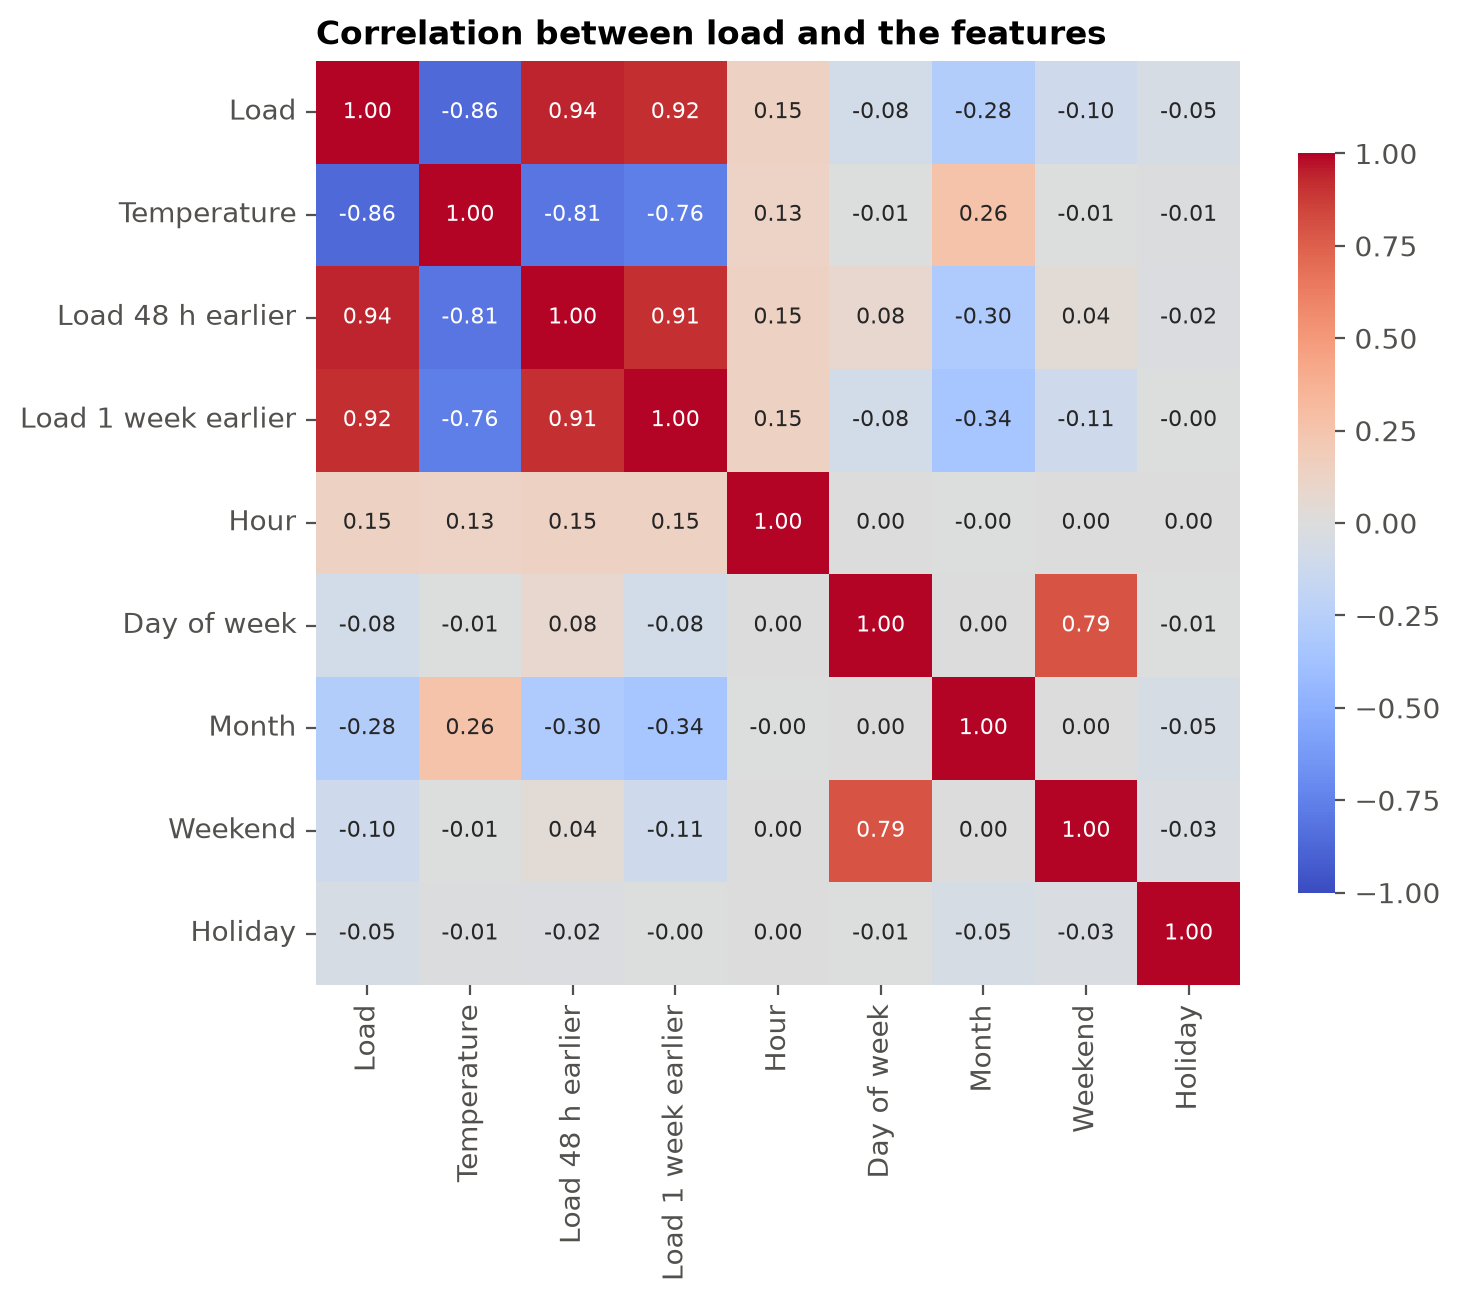

In [10]:
corr = eda.plot_correlation(df)
show("eda_correlation", 640)

Read the strong squares first: load correlates 0.94 with load 48 hours earlier, 0.92 with load one week earlier and -0.86 with temperature. The features are also correlated with each other (the two lags 0.91, temperature against the lags about -0.8), so they partly carry the same information. That matters when we read feature importance later. Then the pale squares: hour of day shows only 0.15, although we just saw a clear daily pattern. The pattern goes up and down during the day, which a straight-line measure cannot see. A pale square does not mean no relationship.

## 2.3 Numbers quoted in the report

In [11]:
eda.main()      # reruns every figure and writes figures/eda_summary.csv
pd.read_csv(ROOT / "figures" / "eda_summary.csv", index_col=0)

Loaded 32687 hourly rows from 2023-01-08 to 2026-09-30
Saved figures/eda_load_over_time.png


Saved figures/eda_load_by_hour.png


Saved figures/eda_load_by_weekday.png
Saved figures/eda_load_by_month.png
Saved figures/eda_load_vs_temperature.png


Saved figures/eda_load_distribution.png
Saved figures/eda_load_box_by_hour.png


Saved figures/eda_load_hour_weekday.png
Saved figures/eda_load_vs_temperature_hourly.png


Saved figures/eda_correlation.png
rows                         32687.00
mean_load_mw                  3924.64
min_load_mw                   1759.48
max_load_mw                   8165.99
winter_to_summer_ratio           2.39
weekday_vs_weekend_pct           8.20
corr_daily_load_temp            -0.95
corr_hourly_load_temp           -0.86
corr_hourly_load_lag_48h         0.94
corr_hourly_load_lag_168h        0.92
corr_hourly_load_hour            0.15
median_load_mw                3604.04


,value
rows,32687.00
mean_load_mw,3924.64
min_load_mw,1759.48
max_load_mw,8165.99
winter_to_summer_ratio,2.39
weekday_vs_weekend_pct,8.20
corr_daily_load_temp,-0.95
corr_hourly_load_temp,-0.86
corr_hourly_load_lag_48h,0.94
corr_hourly_load_lag_168h,0.92


## 2.4 What the EDA tells us to do

- Temperature, calendar and recent load all carry signal, so all three groups go into the models. The ablation test in notebook 3 measures how much each group is worth.
- The temperature relationship is curved, so we compare a linear model against models that can bend.
- The data is a time series with a strong yearly cycle. A random train/test split would let the model see the future, so we split by time.